# Equipment-level incident reports — pipeline walkthrough

This notebook shows, with runnable cells, the per-equipment report pipeline of the branch
`juan/equipment-analysis` (command `uv run dc-equipment`). It has four parts:

1. **The pipeline** — what each step does and why it is built this way.
2. **Step by step on one equipment** — `OUEST1-INV10`: every step of the pipeline is run in its own cell.
3. **Extrapolating to a site-level analysis** — a working prototype of the same recipe with a *site* as the unit.
4. **Running it on another equipment of another site** — `EST1-INV07`, in one call.

All outputs are written to a temporary folder, so running this notebook never modifies
`equipment_reports/`. The full written documentation is in `PIPELINE_EQUIPMENT.md`.

**Requirements:** `uv sync`, then open the notebook with the project kernel (`.venv`). Azure calls need the
`.env` file (see `.env.example`); without it, the notebook runs in *dry-run* mode (prompts are written,
text fields are placeholders).

## 0. Setup

In [1]:
import json
import shutil
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Project root = first parent folder containing pyproject.toml
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
TEMPLATES_DIR = PROJECT_ROOT / "templates"
CSV_PATH = next(
    p
    for p in [PROJECT_ROOT / "data" / "incidents_clusterised_solar.csv", PROJECT_ROOT / "incidents_clusterised_solar.csv"]
    if p.exists()
)

# Every output of this notebook goes to a temporary folder (equipment_reports/ is never touched)
DEMO_DIR = Path(tempfile.gettempdir()) / "equipment_pipeline_demo"
shutil.rmtree(DEMO_DIR, ignore_errors=True)
DEMO_DIR.mkdir(parents=True)

# Azure OpenAI is used only if the .env file exists; otherwise every agent runs in dry-run mode
USE_AZURE = (PROJECT_ROOT / ".env").exists()

pd.set_option("display.max_colwidth", 80)
print(f"Data: {CSV_PATH.relative_to(PROJECT_ROOT)}")
print(f"Azure calls enabled: {USE_AZURE}")

Data: incidents_clusterised_solar.csv
Azure calls enabled: True


In [2]:
def show_markdown(path: Path, max_chars: int | None = None) -> None:
    """Render a generated markdown file (image lines removed: figures are shown separately)."""
    text = "\n".join(line for line in path.read_text(encoding="utf-8").splitlines() if not line.startswith("!["))
    if max_chars and len(text) > max_chars:
        text = text[:max_chars] + "\n\n*[…truncated]*"
    display(Markdown(text))


def show_json(data, max_chars: int = 2500) -> None:
    text = json.dumps(data, ensure_ascii=False, indent=1)
    print(text if len(text) <= max_chars else text[:max_chars] + "\n…")

---
# Part 1 — The pipeline

```
incidents_clusterised_solar.csv  (1 row = 1 incident, with its failure mode = cluster)
        │
        ▼
[1] SELECTION        equipment_stats.compute_criticality / select_equipment
        │            0-100 score vs site and vs fleet → critical equipment P1 / P2
        ▼  for each critical equipment
[2] STATISTICS       equipment_stats.build_equipment_stats
        │            local numbering #1..#n, figures, trends, priorities + "facts"
        ▼
[3] FIGURES + JSON   plot_factory.EquipmentPlotFactory / run_equipment_plotting
        │            figures/<name>.png + json/<name>.json (data drawn) + json/stats.json
        ▼  report_factory only reads json/
[4] AGENTS           report_factory.section_*  — one Azure OpenAI agent per section
        │            role + shared rules + questions + only the data of the section
        │            answers checked in Python (invented numbers, wrong #k) + 1 correction round
        ▼            sections/<section>.md
[5] ASSEMBLY         templates/equipment_report.md → report.md
```

**Three principles**

| Principle | How it is enforced |
| --- | --- |
| The LLM computes nothing | every number, ratio, change, priority and risk level comes from Python; the agents' answers are scanned for numbers absent from their input |
| One specialised agent per section | each `section_*` function has its own role, questions, data subset and JSON schema |
| A figure always comes with its data | each `plot_*` method returns the figure **and** the JSON it draws; the agent commenting the figure receives that JSON |

**Sections and who writes them**

| Section | Written by | Data received |
| --- | --- | --- |
| Title + executive summary | agent *executive-summary writer* (generated last) | key facts, priorities, first actions |
| 1. Key figures | tables in Python + agent *benchmarking analyst* | comparison with the site median, key figures |
| 2. How this report was built | fixed text (no agent) | selection and priority rules |
| 3. Cost timeline | agent *reliability engineer* | `cost_timeline.json`, yearly trend, seasonality, top incidents, close sequences |
| 4. Weather exposure | agent *weather-exposure engineer* | `downtime_weather.json`, `cluster_weather.json` |
| 5. Failure modes | agent *PV failure-analysis expert* | failure modes with their incidents and priorities |
| 6. Root-cause hypotheses | agent *RCA engineer* (confidence set by Python) | failure modes, weather, close sequences |
| 7. Recommendations | agent *O&M planner* (priority set by Python) | failure-mode priorities + the root-cause hypotheses |
| 8. Conclusion | agent *reliability manager* | key facts + prioritised actions |
| Annex — incident register | fixed table (no agent) | register |

---
# Part 2 — Step by step on one equipment: `OUEST1-INV10`

Each cell below runs one step of the pipeline. Together they do exactly what
`uv run dc-equipment --site OUEST1 --equipment OUEST1-INV10` does.

In [3]:
SITE = "OUEST1"
EQUIPMENT = "OUEST1-INV10"

### Step 1 — Load the data and select the critical equipment

In [4]:
from datachallengecapgemini.equipment_stats import (
    build_equipment_stats,
    compute_criticality,
    load_solar_incidents,
    number_incidents,
    select_equipment,
)

df = load_solar_incidents(CSV_PATH)
print(f"{len(df)} solar incidents, {df['site'].nunique()} sites, {df['equipment_id'].nunique()} equipment, "
      f"{df['cluster_name'].nunique()} failure modes")
df[["incident_id", "site", "equipment_id", "date", "severity", "estimated_cost_eur", "downtime_hours",
    "weather_condition", "cluster_name"]].head(3)

899 solar incidents, 3 sites, 31 equipment, 16 failure modes


,incident_id,site,equipment_id,date,severity,estimated_cost_eur,downtime_hours,weather_condition,cluster_name
0,640,Centrale PV Est-1,EST1-INV01,2023-06-23,modérée,4270.90,12.6,conditions nominales,Incendie toiture et panneaux PV
1,321,Centrale PV Est-1,EST1-INV01,2023-08-06,sévère,23040.52,38.4,temps calme,Incendie bâtiment support PV
2,892,Centrale PV Est-1,EST1-INV01,2023-08-24,mineure,118.78,0.6,pluie modérée,Premiers secours incendie PV


The criticality score combines 4 indicators (incidents ×1, severe incidents ×2, cost ×1, downtime ×1)
as robust leave-one-out z-scores, mapped to 0-100 (50 = typical, ≥ 75 = clear outlier). It is computed
against the site (`score_site`) and against the fleet (`score_fleet`). Critical = one of them ≥ 75;
P1 if both, P2 if one.

In [5]:
criticality = compute_criticality(df)
on_site = criticality[criticality["equipment_id"].str.startswith(SITE)]
display(on_site[["equipment_id", "n_incidents", "n_severe", "total_cost", "total_downtime",
                 "score_site", "score_fleet", "equipment_priority", "risk_level"]].round(1))
print("Critical equipment of", SITE, "->", select_equipment(criticality, SITE))

,equipment_id,n_incidents,n_severe,total_cost,total_downtime,score_site,score_fleet,equipment_priority,risk_level
21,OUEST1-INV06,37,9,403751.7,826.3,99.0,99.2,P1,critical
22,OUEST1-INV03,36,8,301163.3,627.8,95.5,98.2,P1,critical
23,OUEST1-INV10,29,6,217557.4,460.9,64.3,86.2,P2,high
24,OUEST1-INV08,34,5,206576.0,486.6,59.5,84.8,P2,high
25,OUEST1-INV04,38,4,247736.1,563.4,56.4,88.8,P2,high
26,OUEST1-INV02,29,5,238751.5,503.9,52.9,85.1,P2,high
27,OUEST1-INV05,36,4,113930.1,309.1,32.0,63.4,-,medium
28,OUEST1-INV01,27,4,152742.1,345.5,22.7,61.0,-,medium
29,OUEST1-INV09,27,2,136629.5,333.7,8.7,40.3,-,low
30,OUEST1-INV07,6,2,73187.9,148.7,2.1,10.6,-,low


Critical equipment of OUEST1 -> ['OUEST1-INV06', 'OUEST1-INV03', 'OUEST1-INV10', 'OUEST1-INV08', 'OUEST1-INV04', 'OUEST1-INV02']


### Step 2 — Statistics and facts

Moderate and severe incidents are numbered `#1..#n` by date for this equipment (the global
`incident_id` never reaches the report).

In [6]:
incidents = number_incidents(df, EQUIPMENT)
incidents[["ref", "date", "severity", "cluster_name", "estimated_cost_eur", "downtime_hours",
           "weather_condition", "days_since_previous"]].head(6)

,ref,date,severity,cluster_name,estimated_cost_eur,downtime_hours,weather_condition,days_since_previous
0,#1,2023-05-15,modérée,Baisse de rendement onduleur,7669.89,24.0,conditions nominales,NaN
1,#2,2023-05-18,modérée,Salissure et nettoyage modules PV,9476.03,24.2,vent modéré,3.0
2,#3,2023-11-21,sévère,Dégradation et court-circuit câblage,49141.68,82.4,temps calme,187.0
3,#4,2023-12-22,sévère,Baisse de rendement onduleur,24164.61,42.6,temps calme,31.0
4,#5,2024-02-26,modérée,Dommages superficiels modules PV,2539.63,7.0,vent fort / tempête,66.0
5,#6,2024-03-23,modérée,Baisse de rendement onduleur,5780.07,14.7,temps calme,26.0


`build_equipment_stats` computes every number of the report. The `facts` are ready-made
sentences for the figures the model used to misread (most costly incident vs most costly failure
mode, ratios, year-on-year changes).

In [7]:
stats = build_equipment_stats(df, criticality, EQUIPMENT)
print("Blocks:", list(stats))
print()
for topic, sentences in stats["facts"].items():
    print(f"[{topic}]")
    for sentence in sentences:
        print("  -", sentence)

Blocks: ['equipment', 'period', 'comparison_with_site_median', 'key_figures', 'yearly_trend', 'seasonality', 'most_costly_incidents', 'close_sequences_within_30_days', 'failure_modes', 'register', 'facts', 'incident_mapping']

[benchmark]
  - Incidents of all severities: 29 on this equipment vs 31.5 for the median equipment of the site (ratio ×0.92, IN LINE with the site median).
  - Severe incidents: 6 on this equipment vs 4.5 for the median equipment of the site (ratio ×1.33, ABOVE the site median).
  - Estimated cost of all incidents: 217 557 EUR on this equipment vs 212 067 EUR for the median equipment of the site (ratio ×1.03, IN LINE with the site median).
  - Downtime of all incidents: 460.9 h on this equipment vs 473.8 h for the median equipment of the site (ratio ×0.97, IN LINE with the site median).
[cost]
  - Moderate and severe incidents: 15 (6 severe), 206 762 EUR in total; severe incidents account for 74.9% of this cost.
  - The most costly single incident is #3 (Dégradat

In [8]:
# Priority of each failure mode (inherited by the recommendations that target it)
pd.DataFrame(stats["failure_modes"])[
    ["failure_mode", "recommendation_priority", "priority_reason", "n_incidents", "n_severe", "cost_share_pct"]
]

,failure_mode,recommendation_priority,priority_reason,n_incidents,n_severe,cost_share_pct
0,Incendie bâtiment support PV,P1,2 severe incident(s) + 24.7% of the equipment cost + 1 recurrence(s) within ...,2,2,24.7
1,Dégradation et court-circuit câblage,P1,1 severe incident(s) + 23.8% of the equipment cost,1,1,23.8
2,Baisse de rendement onduleur,P1,1 severe incident(s) + 21.6% of the equipment cost,4,1,21.6
3,Salissure et nettoyage modules PV,P1,1 severe incident(s) + 1 recurrence(s) within 90 days,4,1,15.5
4,Défaillance chaîne et boîtier de jonction,P2,"1 severe incident(s), 8.5% of the cost, no recurrence within 90 days",1,1,8.5
5,Incendie toiture et panneaux PV,P3,no severe incident and 4.7% of the cost,2,0,4.7
6,Dommages superficiels modules PV,P3,no severe incident and 1.2% of the cost,1,0,1.2


### Step 3 — Figures + JSON

Each `plot_*` method of `EquipmentPlotFactory` returns an `EquipmentPlot(figure, data)`: the figure and
the data it draws, which is what the agent of the section receives.

In [9]:
from datachallengecapgemini.plot_factory import PLOT_METHOD_PREFIX, EquipmentPlotFactory

equipment_dir = DEMO_DIR / SITE / EQUIPMENT
(equipment_dir / "figures").mkdir(parents=True, exist_ok=True)
(equipment_dir / "json").mkdir(parents=True, exist_ok=True)

factory = EquipmentPlotFactory(df, EQUIPMENT)
for method in EquipmentPlotFactory.plot_method_names():
    plot = getattr(factory, method)()
    name = method.removeprefix(PLOT_METHOD_PREFIX)
    plot.figure.savefig(equipment_dir / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")
    (equipment_dir / "json" / f"{name}.json").write_text(
        json.dumps(plot.data, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{method:<24} -> figures/{name}.png + json/{name}.json")

(equipment_dir / "json" / "stats.json").write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
print("stats.json written")

plot_cluster_weather     -> figures/cluster_weather.png + json/cluster_weather.json


plot_cost_timeline       -> figures/cost_timeline.png + json/cost_timeline.json


plot_downtime_weather    -> figures/downtime_weather.png + json/downtime_weather.json
stats.json written


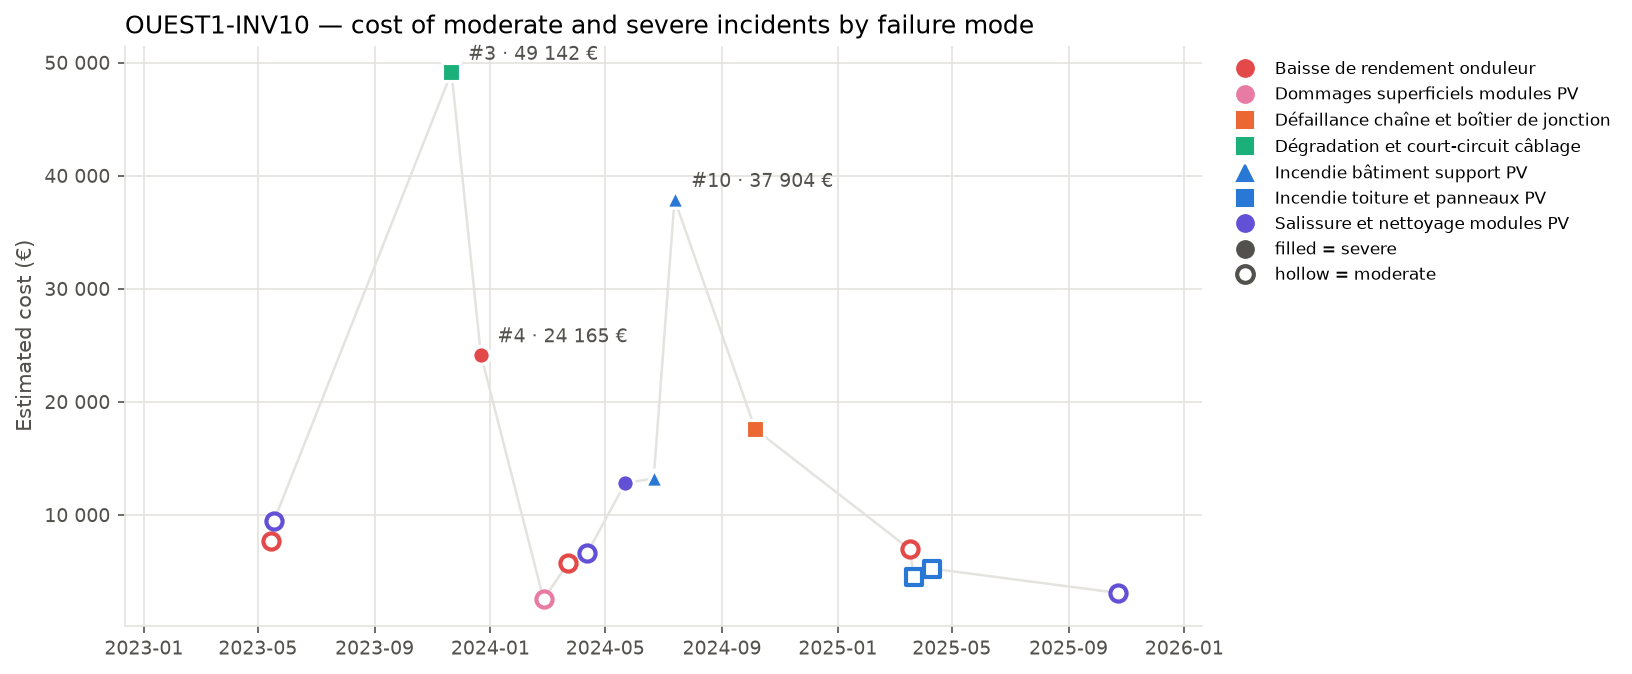

labelled_incidents: ['#3', '#10', '#4']
[
 {
  "ref": "#1",
  "date": "2023-05-15",
  "severity": "modérée",
  "failure_mode": "Baisse de rendement onduleur",
  "cost_eur": 7670,
  "downtime_h": 24.0,
  "weather_condition": "conditions nominales",
  "days_since_previous_incident": null,
  "days_since_previous_same_failure_mode": null
 },
 {
  "ref": "#2",
  "date": "2023-05-18",
  "severity": "modérée",
  "failure_mode": "Salissure et nettoyage modules PV",
  "cost_eur": 9476,
  "downtime_h": 24.2,
  "weather_condition": "vent modéré",
  "days_since_previous_incident": 3,
  "days_since_previous_same_failure_mode": null
 },
 {
  "ref": "#3",
  "date": "2023-11-21",
  "severity": "sévère",
  "failure_mode": "Dégradation et court-circuit câblage",
  "cost_eur": 49142,
  "downtime_h": 82.4,
  "weather_condition": "temps calme",
  "days_since_previous_incident": 187,
  "days_since_previous_same_failure_mode": null
 }
]


In [10]:
display(Image(filename=equipment_dir / "figures" / "cost_timeline.png"))
timeline = json.loads((equipment_dir / "json" / "cost_timeline.json").read_text(encoding="utf-8"))
print("labelled_incidents:", timeline["labelled_incidents"])
show_json(timeline["points"][:3])

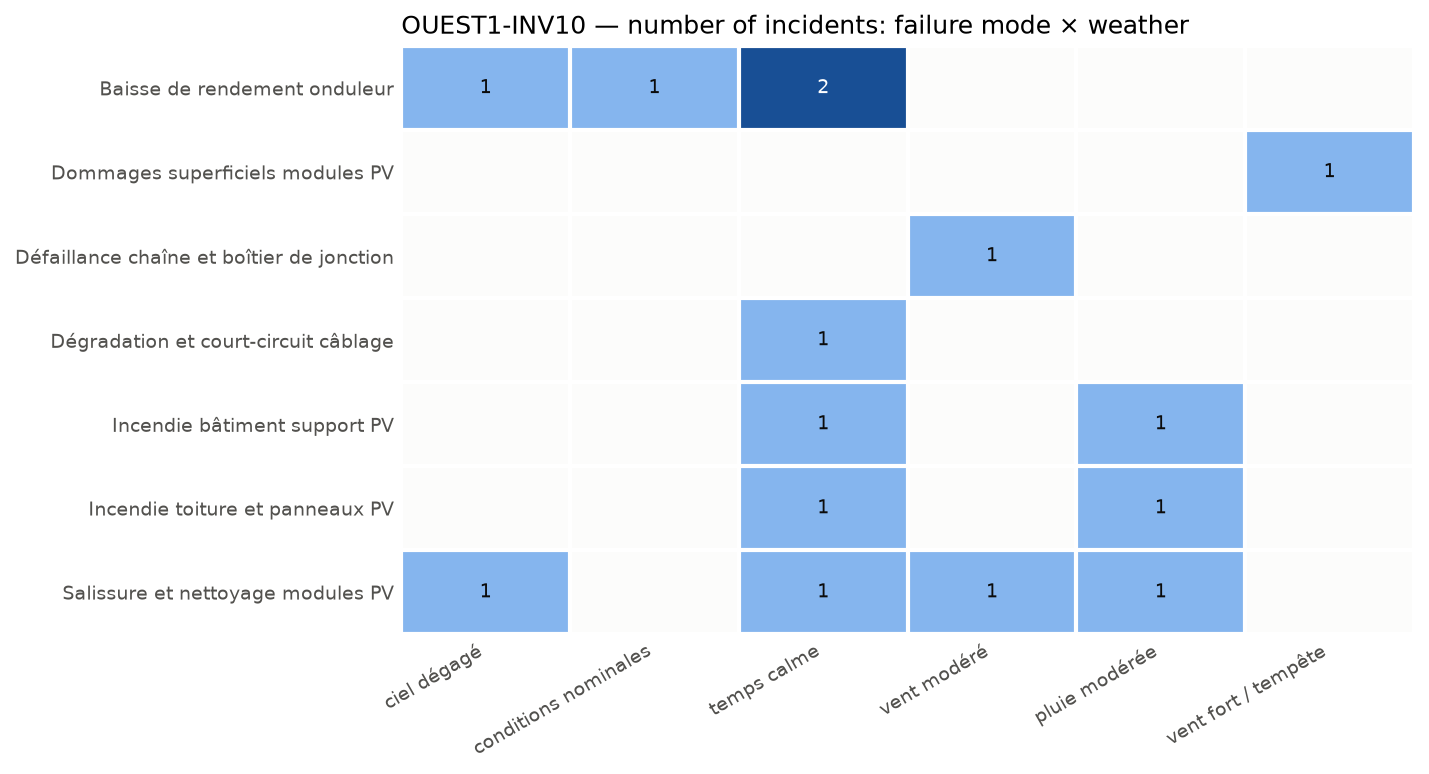

{
 "figure": "Failure modes vs weather condition",
 "how_to_read": "Number of incidents per failure mode (rows) and weather condition. A weather condition absent from a failure mode's row never occurred with that failure mode.",
 "matrix": {
  "Baisse de rendement onduleur": {
   "ciel dégagé": 1,
   "conditions nominales": 1,
   "temps calme": 2
  },
  "Dommages superficiels modules PV": {
   "vent fort / tempête": 1
  },
  "Défaillance chaîne et boîtier de jonction": {
   "vent modéré": 1
  },
  "Dégradation et court-circuit câblage": {
   "temps calme": 1
  },
  "Incendie bâtiment support PV": {
   "temps calme": 1,
   "pluie modérée": 1
  },
  "Incendie toiture et panneaux PV": {
   "temps calme": 1,
   "pluie modérée": 1
  },
  "Salissure et nettoyage modules PV": {
   "ciel dégagé": 1,
   "temps calme": 1,
   "vent modéré": 1,
   "pluie modérée": 1
  }
 }
}


In [11]:
display(Image(filename=equipment_dir / "figures" / "cluster_weather.png"))
show_json(json.loads((equipment_dir / "json" / "cluster_weather.json").read_text(encoding="utf-8")))

### Step 4 — One agent per section

`report_factory` only reads `json/`. A `SectionContext` holds the inputs of the report and the
answers collected so far; each `section_*` function calls `ctx.ask(...)` with its own role,
questions, data subset and output schema.

**Cache:** each answer is stored in `sections/<section>.llm.json` with the hash of its prompt. We
first copy the answers already generated in `equipment_reports/` into the demo folder: since the
prompts are identical, they are reused and no Azure call is made for this equipment.

In [12]:
from datachallengecapgemini.report_factory import EQUIPMENT_SECTIONS, SectionContext, get_azure_client

sections_dir = equipment_dir / "sections"
sections_dir.mkdir(exist_ok=True)
committed = PROJECT_ROOT / "equipment_reports" / SITE / EQUIPMENT / "sections"
for cached in committed.glob("*.llm.json"):
    shutil.copy(cached, sections_dir / cached.name)
print(f"{len(list(sections_dir.glob('*.llm.json')))} cached agent answers copied")

client, deployment = get_azure_client() if USE_AZURE else (None, None)
ctx = SectionContext(
    equipment_id=EQUIPMENT,
    stats=json.loads((equipment_dir / "json" / "stats.json").read_text(encoding="utf-8")),
    figures={p.stem: json.loads(p.read_text(encoding="utf-8"))
             for p in (equipment_dir / "json").glob("*.json") if p.stem != "stats"},
    sections_dir=sections_dir,
    client=client,
    deployment=deployment,
    dry_run=not USE_AZURE,
)

8 cached agent answers copied


Let us run **one** section first, the cost timeline, and look at what its agent receives.
The prompt is saved next to the answer (`sections/cost_timeline.prompt.md`).

In [13]:
from datachallengecapgemini.report_factory import section_cost_timeline

markdown = section_cost_timeline(ctx)
prompt = (sections_dir / "cost_timeline.prompt.md").read_text(encoding="utf-8")
system, user = prompt.split("# User", 1)
print(system[:1200], "\n…\n")
print("# User" + user[:1500], "\n…")

# System

You are a reliability engineer who analyses the cost history and recurrence of incidents on PV inverters.

You write one section of an equipment-level incident report for asset managers and maintenance planners of utility-scale photovoltaic plants. The equipment is a PV inverter and the DC field upstream of it.

# Rules
1. NO CALCULATIONS. Do not add, subtract, average, compare numerically, compute percentages, ratios, durations or date differences. Every number you write must be copied from the input (rounding allowed). If a figure you would like to quote is not in the input, make the point without a number.
2. `facts` are verified, ready-made sentences: when you quote one of their figures, copy it exactly with the meaning given there (e.g. do not swap "most costly incident" and "most costly failure mode", or the ratio of one indicator for another).
3. Refer to incidents ONLY by their local number as written in the input (e.g. "#3"). Cite an incident for a failure mode only 

In [14]:
# The answer: one field per question (JSON schema), then rendered with the Python tables
show_json(ctx.answers["cost_timeline"])
(sections_dir / "cost_timeline.md").write_text(markdown + "\n", encoding="utf-8")
show_markdown(sections_dir / "cost_timeline.md")

{
 "trend": "The overall cost of incidents has decreased significantly from 2023 to 2025, with a notable drop of over three-quarters in total costs. Incident frequency increased slightly in 2024 compared to 2023 but then declined in 2025, reflecting a downward trend in costs despite some fluctuations.",
 "dominant_incidents": "The most costly incident was #3, involving degradation and short-circuiting of wiring, accounting for nearly a quarter of the total incident costs. The failure mode that dominates costs is incendie bâtiment support PV, with two incidents totaling over a quarter of the overall costs.",
 "sequences_and_recurrences": "Close sequences of incidents occurred within days of each other, such as #1 and #2 in May 2023, and multiple incidents involving the same failure modes like 'Baisse de rendement onduleur' and 'Salissure et nettoyage modules PV' occurring within weeks in early 2024. The recurrence of the same failure modes within short periods indicates potential recurr

## 3. Cost timeline


*Estimated cost of each moderate (hollow) and severe (filled) incident. Colour = family of failure modes, marker shape = failure mode; the three most costly incidents are labelled.*

| Year | Incidents | Severe | Cost (EUR) | Cost vs previous year | Downtime (h) |
| --- | --- | --- | --- | --- | --- |
| 2023 | 4 | 2 | 90 452 |  | 173.2 |
| 2024 | 7 | 4 | 96 489 | +6.7 % | 180.7 |
| 2025 | 4 | 0 | 19 821 | -79.5 % | 60.1 |

**Trend.** The overall cost of incidents has decreased significantly from 2023 to 2025, with a notable drop of over three-quarters in total costs. Incident frequency increased slightly in 2024 compared to 2023 but then declined in 2025, reflecting a downward trend in costs despite some fluctuations.

**Dominant incidents.** The most costly incident was #3, involving degradation and short-circuiting of wiring, accounting for nearly a quarter of the total incident costs. The failure mode that dominates costs is incendie bâtiment support PV, with two incidents totaling over a quarter of the overall costs.

**Sequences and recurrences.** Close sequences of incidents occurred within days of each other, such as #1 and #2 in May 2023, and multiple incidents involving the same failure modes like 'Baisse de rendement onduleur' and 'Salissure et nettoyage modules PV' occurring within weeks in early 2024. The recurrence of the same failure modes within short periods indicates potential recurring issues.

**Seasonality.** Incidents occurred across all seasons, with spring and autumn showing higher incident counts and costs. Winter and summer had fewer incidents, but the sample size is indicative only, as fewer than three incidents were recorded in those seasons.

Now every section, in generation order: the conclusion and the executive summary come last
because they receive the prioritised actions. Python checks each answer; problems left after the
correction round would be listed in `checks.txt`.

In [15]:
context = {}
for name, build_section in EQUIPMENT_SECTIONS.items():
    markdown = build_section(ctx)
    (sections_dir / f"{name}.md").write_text(markdown + "\n", encoding="utf-8")
    context[f"section_{name}"] = markdown.replace("](../figures/", "](figures/")
    agent = "agent" if name in ctx.answers else "Python only"
    print(f"{name:<18} {agent:<12} {len(markdown):>6} characters")

print("\nChecks left after correction:", ctx.warnings or "none")

key_figures        agent          1610 characters
methodology        Python only    2250 characters
cost_timeline      agent          1766 characters
weather            agent          2096 characters
failure_modes      agent          3646 characters
root_causes        agent          1415 characters
recommendations    agent          2224 characters
conclusion         agent           396 characters
summary            agent           865 characters
incident_register  Python only    1579 characters

Checks left after correction: none


In [16]:
show_markdown(sections_dir / "recommendations.md")

## 7. Recommendations

| Priority | Action | Type | Failure mode addressed | Expected impact |
| --- | --- | --- | --- | --- |
| P1 | Perform thermography inspections on the inverter to identify hot spots indicating potential failure modes. | monitoring | Baisse de rendement onduleur | Early detection of thermal issues could prevent severe incidents, which account for 21.6% of the equipment cost. |
| P1 | Conduct IV-curve tracing and insulation resistance tests on the DC field upstream to detect degradation or short circuits. | preventive | Dégradation et court-circuit câblage | Identifying electrical degradation early can reduce the risk of severe incidents, which represent 23.8% of the equipment cost. |
| P1 | Implement a regular connector torque check schedule for all DC field connections. | preventive | Dégradation et court-circuit câblage | Proper torque maintenance can mitigate connection failures, potentially reducing the recurrence of incidents. |
| P1 | Inspect and upgrade surge protection devices in the DC field to prevent damage from electrical surges. | preventive | Incendie bâtiment support PV | Enhanced surge protection can lower the risk of fire incidents, which are responsible for 24.7% of the equipment cost and have recurred within 90 days. |
| P1 | Establish a cleaning schedule for modules to reduce dirt accumulation, especially under conditions of 'ciel dégagé' and 'vent modéré'. | preventive | Salissure et nettoyage modules PV | Regular cleaning can decrease the likelihood of severe incidents, which account for 15.5% of the equipment cost and have a recurrence within 90 days. |
| P1 | Maintain a stock of critical spare parts for the inverter and DC connectors to enable quick corrective actions. | spare parts | Baisse de rendement onduleur | Availability of spare parts can reduce downtime and mitigate the impact of failures related to inverter performance. |
| P3 | Perform fire-risk inspections focusing on support structures and PV panels, especially during calm weather conditions. | monitoring | Incendie toiture et panneaux PV | Proactive inspections can prevent fire incidents, which have no severe incidents but account for 4.7% of the cost and have recurred once. |

### Step 5 — Assembly

In [17]:
from datachallengecapgemini.report_factory import EQUIPMENT_TEMPLATE_NAME, fill_template

template = (TEMPLATES_DIR / EQUIPMENT_TEMPLATE_NAME).read_text(encoding="utf-8")
print(template)
report_path = equipment_dir / "report.md"
report_path.write_text(fill_template(template, context), encoding="utf-8")
show_markdown(report_path, max_chars=2500)

{{ section_summary }}

---

{{ section_key_figures }}

{{ section_methodology }}

{{ section_cost_timeline }}

{{ section_weather }}

{{ section_failure_modes }}

{{ section_root_causes }}

{{ section_recommendations }}

{{ section_conclusion }}

---

{{ section_incident_register }}



# OUEST1-INV10 Inverter and DC Field Failure Modes and Incidents

**Equipment:** OUEST1-INV10 · **Site:** Centrale PV Ouest-1 · **Asset type:** PV inverter · **Generated on:** 2026-10-20

> The PV inverter and the upstream DC field at OUEST1-INV10 have experienced multiple incidents, with severe failures including wiring degradation and building support fires. The total cost of moderate and severe incidents is over 206,762 EUR, with the most costly incident at 49,142 EUR. Given the equipment's high risk level and criticality, initial actions should focus on thermography inspections, testing the DC field, and upgrading surge protection devices.

**Equipment priority: P2 · Risk level: HIGH** — Criticality score 64.3 (below the threshold of 75) against the other equipment of the site and 86.2 (at or above the threshold of 75) against the whole solar fleet.

---

## 1. Key figures

| Indicator | This equipment | Median equipment of the site | Ratio |
| --- | --- | --- | --- |
| Incidents (all severities) | 29 | 31.5 | ×0.92 |
| Severe incidents | 6 | 4.5 | ×1.33 |
| Total estimated cost (all severities) | 217 557 EUR | 212 067 EUR | ×1.03 |
| Total downtime (all severities) | 460.9 h | 473.8 h | ×0.97 |

| Moderate and severe incidents (scope of this report) | Value |
| --- | --- |
| Incidents analysed | 15 (9 moderate · 6 severe) |
| Period covered | 2023-02-19 → 2025-12-30 |
| Total estimated cost | 206 762 EUR (74.9 % from severe incidents) |
| Average cost per incident | 13 784 EUR |
| Total downtime | 414.0 h |
| Average interval between incidents | 64 days |
| Most costly failure mode | Incendie bâtiment support PV (51 131 EUR) |
| Weather with most downtime | temps calme (196.5 h) |

This equipment has a slightly lower number of incidents compared to the site median, with a ratio of 0.92, indicating it is in line with other equipment. However, it exhibits a higher ratio of severe incidents at 1.33, meaning it experiences more severe failures than most equipment at the site. Its cost and downtime are also in line with the median, with ratios close to 1.0. It was selected because its criticality score of 64.3 is below the threshold of 75 within the site but at or above 75 compared to the entire fleet, highlighting its importance. The high risk level and P2 priority emphasize the need for close monitoring. Most of the incident cost (74.9%) is concentrated on severe incidents, indicating a significant impact from the most serious failures.

## 2. How this r

*[…truncated]*

**Same result in one call** (what `uv run dc-equipment` runs):

```python
from datachallengecapgemini.plot_factory import run_equipment_plotting
from datachallengecapgemini.report_factory import run_equipment_reporting

run_equipment_plotting(df, criticality, ["OUEST1-INV10"], site_dir)
run_equipment_reporting(["OUEST1-INV10"], site_dir, TEMPLATES_DIR)
```

Part 4 uses exactly these two calls on another equipment.

---
# Part 3 — Extrapolating the pipeline to a site-level analysis

The pipeline does not depend on the unit being a piece of equipment. To change the unit, define:

| | What to define | Equipment report | Site report (this prototype) |
| --- | --- | --- | --- |
| 1 | the **unit** | one inverter | one site |
| 2 | its **peers** | the other equipment of the site / the fleet | the other sites of the fleet |
| 3 | the **statistics + facts** | `build_equipment_stats` | `build_site_stats` below |
| 4 | the **figures + JSON** | `EquipmentPlotFactory` | `plot_equipment_failure_modes` below |
| 5 | the **sections** | `section_*` in `report_factory` | `section_systemic_vs_local` below |

What is reused unchanged: `SectionContext.ask` (prompt, cache, checks, correction round),
`call_azure`, `_md_table`, `fill_template`. The only coupling to generalise in a real implementation:
`SectionContext` reads the unit's site from `stats["equipment"]["site"]`, and `SHARED_RULES` describes
the unit as "a PV inverter" — both would become parameters.

The prototype below builds one site-level section: **are the failure modes of the site systemic
(present on many equipment) or local (concentrated on one)?**

### 3.1 Site statistics + facts (all computed in Python)

In [18]:
from datachallengecapgemini.equipment_stats import FOCUS_SEVERITIES, SEVERE, format_eur, site_code


def build_site_stats(df: pd.DataFrame, criticality: pd.DataFrame, site: str) -> dict:
    """Statistics of one site: comparison with the median site, failure-mode spread, equipment ranking."""
    df = df.assign(site_code=df["equipment_id"].map(site_code))
    per_site = df.groupby("site_code").agg(
        n_incidents=("incident_id", "count"),
        n_severe=("severity", lambda s: int((s == SEVERE).sum())),
        total_cost=("estimated_cost_eur", "sum"),
        total_downtime=("downtime_hours", "sum"),
    )
    median = per_site.median()
    comparison = {
        indicator: {
            "this_site": round(float(per_site.loc[site, indicator]), 1 if indicator == "total_downtime" else None),
            "median_site": round(float(median[indicator]), 1 if indicator == "total_downtime" else None),
            "ratio_to_median_site": round(float(per_site.loc[site, indicator] / median[indicator]), 2),
        }
        for indicator in per_site.columns
    }

    on_site = df[df["site_code"] == site]
    n_equipment = on_site["equipment_id"].nunique()
    focus = on_site[on_site["severity"].isin(FOCUS_SEVERITIES)]
    modes = []
    for mode, g in focus.groupby("cluster_name"):
        affected = g["equipment_id"].nunique()
        spread = "systemic" if affected >= max(3, n_equipment / 2) else "local" if affected == 1 else "partial"
        modes.append({
            "failure_mode": mode,
            "n_incidents": len(g),
            "n_severe": int((g["severity"] == SEVERE).sum()),
            "cost_total_eur": round(float(g["estimated_cost_eur"].sum())),
            "n_equipment_affected": affected,
            "spread": spread,
            "equipment_affected": sorted(g["equipment_id"].unique()),
        })
    modes.sort(key=lambda m: m["cost_total_eur"], reverse=True)

    facts = [
        f"{label}: {fmt(c['this_site'])} on this site vs {fmt(c['median_site'])} for the median site "
        f"(ratio ×{c['ratio_to_median_site']})."
        for label, fmt, c in zip(["Incidents", "Severe incidents", "Total cost (EUR)", "Downtime (h)"],
                                 [str, str, format_eur, str], comparison.values())
    ] + [
        f"{m['failure_mode']}: {m['n_incidents']} incident(s) on {m['n_equipment_affected']} of the {n_equipment} "
        f"equipment, {format_eur(m['cost_total_eur'])} EUR ({m['spread']})."
        for m in modes
    ]
    ranking = criticality[criticality["equipment_id"].map(site_code) == site]
    return {
        # SectionContext reads the unit's site here (the coupling to generalise)
        "equipment": {"equipment_id": site, "site": on_site["site"].iloc[0]},
        "register": [],
        "n_equipment": n_equipment,
        "comparison_with_median_site": comparison,
        "failure_modes": modes,
        "equipment_ranking": ranking[["equipment_id", "score_site", "equipment_priority"]].round(1).to_dict("records"),
        "facts": {"site": facts},
    }


site_stats = build_site_stats(df, criticality, SITE)
for sentence in site_stats["facts"]["site"]:
    print("-", sentence)

- Incidents: 299 on this site vs 300 for the median site (ratio ×1.0).
- Severe incidents: 49 on this site vs 39 for the median site (ratio ×1.26).
- Total cost (EUR): 2 092 026 on this site vs 1 208 188 for the median site (ratio ×1.73).
- Downtime (h): 4605.9 on this site vs 2777.6 for the median site (ratio ×1.66).
- Dommages superficiels modules PV: 37 incident(s) on 9 of the 10 equipment, 546 386 EUR (systemic).
- Dégradation et court-circuit câblage: 19 incident(s) on 8 of the 10 equipment, 431 863 EUR (systemic).
- Défaillance chaîne et boîtier de jonction: 10 incident(s) on 7 of the 10 equipment, 250 720 EUR (systemic).
- Incendie toiture et panneaux PV: 21 incident(s) on 9 of the 10 equipment, 196 267 EUR (systemic).
- Incendie bâtiment support PV: 8 incident(s) on 5 of the 10 equipment, 184 581 EUR (systemic).
- Baisse de rendement onduleur: 12 incident(s) on 5 of the 10 equipment, 177 578 EUR (systemic).
- Salissure et nettoyage modules PV: 10 incident(s) on 5 of the 10 equi

### 3.2 A site figure and its JSON (same `EquipmentPlot(figure, data)` contract)

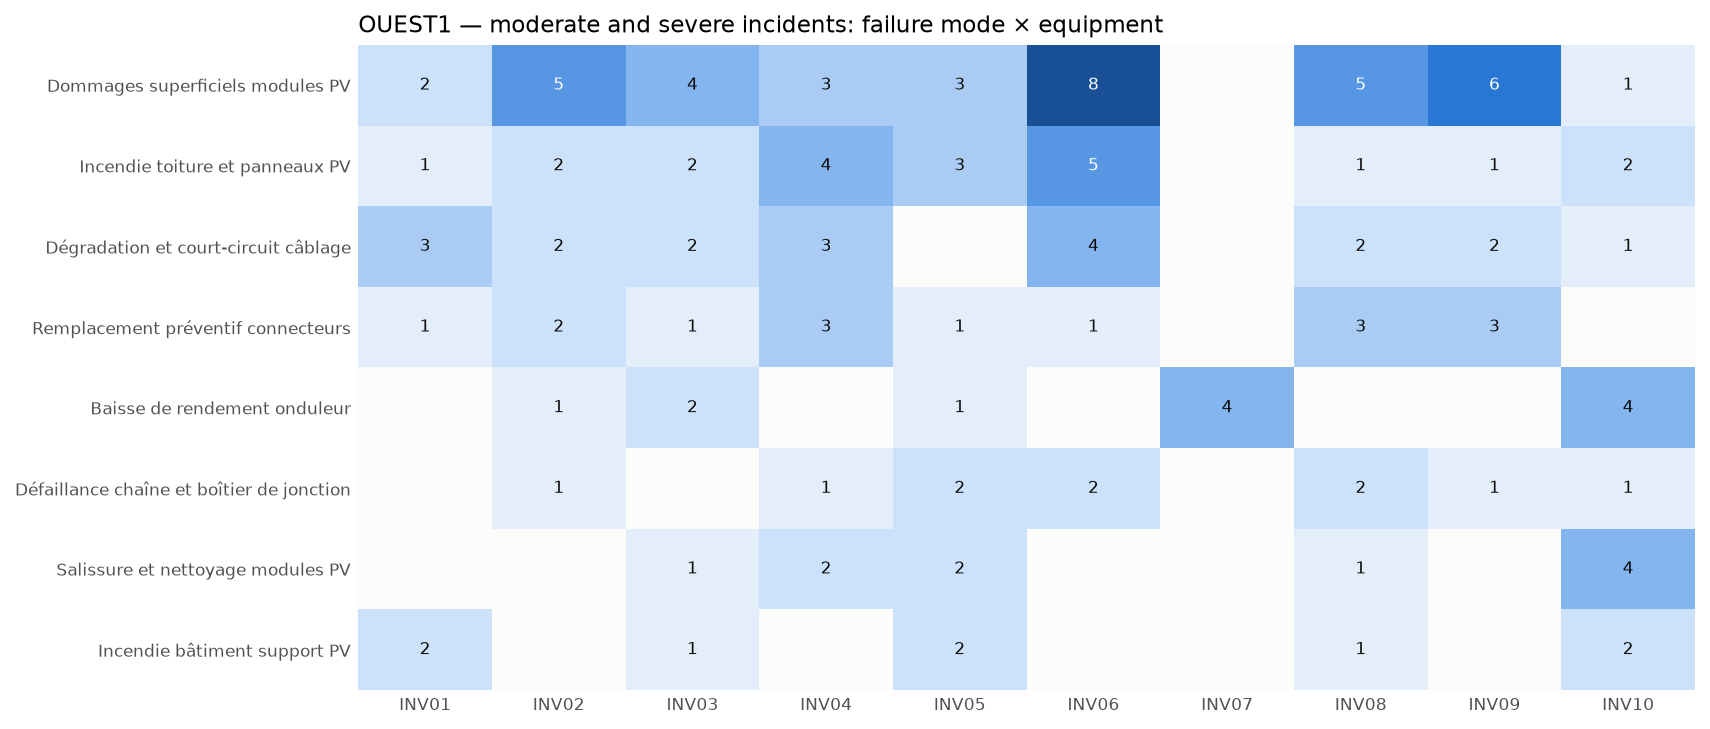

In [19]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure

from datachallengecapgemini.plot_factory import SEQUENTIAL_BLUES, TEXT_SECONDARY, EquipmentPlot


def plot_equipment_failure_modes(df: pd.DataFrame, site: str) -> EquipmentPlot:
    """Heatmap: moderate/severe incidents per equipment (columns) and failure mode (rows)."""
    d = df[(df["equipment_id"].map(site_code) == site) & df["severity"].isin(FOCUS_SEVERITIES)]
    ct = pd.crosstab(d["cluster_name"], d["equipment_id"])
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
    fig = Figure(figsize=(0.7 * ct.shape[1] + 4.5, 0.42 * ct.shape[0] + 1.6))
    ax = fig.subplots()
    vmax = max(int(ct.values.max()), 1)
    ax.imshow(ct.values, cmap=LinearSegmentedColormap.from_list("blues", SEQUENTIAL_BLUES), vmin=0, vmax=vmax,
              aspect="auto")
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            if ct.values[i, j]:
                ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=8,
                        color="white" if ct.values[i, j] > 0.55 * vmax else "#0b0b0b")
    ax.set_xticks(range(ct.shape[1]), [c.split("-")[1] for c in ct.columns], fontsize=8, color=TEXT_SECONDARY)
    ax.set_yticks(range(ct.shape[0]), ct.index, fontsize=8, color=TEXT_SECONDARY)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{site} — moderate and severe incidents: failure mode × equipment", loc="left", fontsize=11)
    fig.tight_layout()
    data = {"figure": "Failure modes vs equipment of the site",
            "matrix": {mode: {eq: int(n) for eq, n in row.items() if n} for mode, row in ct.iterrows()}}
    return EquipmentPlot(fig, data)


site_dir = DEMO_DIR / f"site_{SITE}"
(site_dir / "figures").mkdir(parents=True, exist_ok=True)
(site_dir / "sections").mkdir(exist_ok=True)
site_plot = plot_equipment_failure_modes(df, SITE)
site_plot.figure.savefig(site_dir / "figures" / "equipment_failure_modes.png", dpi=150, bbox_inches="tight")
display(Image(filename=site_dir / "figures" / "equipment_failure_modes.png"))

### 3.3 A site-level section with its own agent

Same pattern as the equipment sections: a role, questions, the data of the section, a strict
schema and a Python check (here: every failure mode named must exist on the site).

In [20]:
from datachallengecapgemini.report_factory import _list, _md_table, _object, _text


def section_systemic_vs_local(ctx: SectionContext) -> str:
    """Site section — are the failure modes systemic (many equipment) or local (one equipment)?"""
    modes = ctx.stats["failure_modes"]
    names = {m["failure_mode"] for m in modes}

    def check(answer: dict) -> list[str]:
        unknown = [m for m in answer["systemic_issues"] + answer["local_issues"] if m not in names]
        return [f"unknown failure modes: {'; '.join(unknown)}"] if unknown else []

    answer = ctx.ask(
        "systemic_vs_local",
        "3. Systemic vs local failure modes",
        role="a reliability engineer who compares PV inverters within a site to separate site-wide issues from "
             "equipment-specific ones.",
        questions=[
            "Which failure modes are systemic (spread over many equipment of the site) and which are local? "
            "Use the `spread` field as given.",
            "For the most costly systemic failure modes, what does a site-wide cause suggest (design, installation, "
            "environment) compared with a local cause (one faulty component)?",
            "Which equipment should be inspected first, according to the given ranking and priorities?",
        ],
        data={
            "failure_modes": modes,
            "equipment_ranking": ctx.stats["equipment_ranking"],
            "failure_modes_vs_equipment_figure": ctx.figures["equipment_failure_modes"],
            "facts": ctx.facts["site"],
        },
        schema=_object({
            "systemic_issues": _list(_text("Failure mode name, verbatim."), "Systemic failure modes."),
            "local_issues": _list(_text("Failure mode name, verbatim."), "Local failure modes."),
            "analysis": _text("Answer to questions 1-2 (3-5 sentences)."),
            "inspection_order": _text("Answer to question 3 (1-2 sentences)."),
        }),
        check=check,
    )
    table = _md_table(modes, {"failure_mode": "Failure mode", "n_incidents": "Incidents",
                              "n_equipment_affected": "Equipment affected", "spread": "Spread",
                              "cost_total_eur": "Cost (EUR)"})
    return "\n\n".join(["## 3. Systemic vs local failure modes", table, answer["analysis"],
                        f"**Inspection order.** {answer['inspection_order']}"])


site_ctx = SectionContext(
    equipment_id=SITE,
    stats=site_stats,
    figures={"equipment_failure_modes": site_plot.data},
    sections_dir=site_dir / "sections",
    client=client,
    deployment=deployment,
    dry_run=not USE_AZURE,
)
site_markdown = section_systemic_vs_local(site_ctx)
(site_dir / "sections" / "systemic_vs_local.md").write_text(site_markdown + "\n", encoding="utf-8")
print("Checks:", site_ctx.warnings or "none")
show_markdown(site_dir / "sections" / "systemic_vs_local.md")

  systemic_vs_local: asking Azure OpenAI


Checks: none


## 3. Systemic vs local failure modes

| Failure mode | Incidents | Equipment affected | Spread | Cost (EUR) |
| --- | --- | --- | --- | --- |
| Dommages superficiels modules PV | 37 | 9 | systemic | 546386 |
| Dégradation et court-circuit câblage | 19 | 8 | systemic | 431863 |
| Défaillance chaîne et boîtier de jonction | 10 | 7 | systemic | 250720 |
| Incendie toiture et panneaux PV | 21 | 9 | systemic | 196267 |
| Incendie bâtiment support PV | 8 | 5 | systemic | 184581 |
| Baisse de rendement onduleur | 12 | 5 | systemic | 177578 |
| Salissure et nettoyage modules PV | 10 | 5 | systemic | 109365 |
| Remplacement préventif connecteurs | 15 | 8 | systemic | 72820 |

Most of the failure modes are systemic, affecting many equipment units across the site. The most costly systemic failure modes suggest that site-wide causes such as environmental factors or design issues are likely contributors, rather than isolated component faults. Equipment with the highest site scores and priorities should be inspected first, notably OUEST1-INV06 and OUEST1-INV03, which are ranked P1.

**Inspection order.** Inspect OUEST1-INV06 and OUEST1-INV03 first, as they have the highest site scores and priorities.

**To turn this prototype into a full site pipeline**

1. move `build_site_stats` to `src/datachallengecapgemini/site_stats.py` and add the other blocks
   (yearly trend, weather, `#k` numbering per site, more facts);
2. add a `SitePlotFactory` in `plot_factory.py` with `plot_*` methods returning `EquipmentPlot`;
3. add `section_site_*` functions and a `SITE_SECTIONS` dict in `report_factory.py`, plus
   `templates/site_report.md` with `{{ section_<x> }}` markers;
4. add a `dc-site` command modelled on `main_equipment`. A site report can also receive, as the data of
   one section, the `sections/summary.llm.json` already generated for its critical equipment.

---
# Part 4 — Running the pipeline on another equipment of another site

To analyse any equipment, only two variables change. Here: `EST1-INV07`, the most critical equipment of
the site Est-1 (P1). From a terminal, the equivalent is:

```bash
uv run dc-equipment --site EST1 --equipment EST1-INV07
```

In [21]:
SITE_2 = "EST1"
print("Critical equipment of", SITE_2, "->", select_equipment(criticality, SITE_2))
EQUIPMENT_2 = "EST1-INV07"

Critical equipment of EST1 -> ['EST1-INV07', 'EST1-INV03', 'EST1-INV02']


In [22]:
from datachallengecapgemini.plot_factory import run_equipment_plotting
from datachallengecapgemini.report_factory import run_equipment_reporting

from contextlib import chdir

# Run from the demo folder with a relative site folder, so that the printed paths stay short
with chdir(DEMO_DIR):
    run_equipment_plotting(df, criticality, [EQUIPMENT_2], Path(SITE_2))
    run_equipment_reporting([EQUIPMENT_2], Path(SITE_2), TEMPLATES_DIR, dry_run=not USE_AZURE)
site_dir_2 = DEMO_DIR / SITE_2

Saved figures and JSON of EST1-INV07 in EST1\EST1-INV07


- EST1-INV07
  key_figures: asking Azure OpenAI


  cost_timeline: asking Azure OpenAI


  weather: asking Azure OpenAI


  failure_modes: asking Azure OpenAI


  failure_modes: numbers not found in the input: 53, 14400, 15200, 15600 — copy every number exactly from the input, or make the point without a number — asking again


... (2 outputs left out)

  recommendations: asking Azure OpenAI


  conclusion: asking Azure OpenAI


  summary: asking Azure OpenAI


  Saved EST1\EST1-INV07\report.md
Done. 27465 input + 3489 output tokens (estimated 0.0041 USD at GPT-4.1 nano rates). Reports are in EST1


In [23]:
equipment_dir_2 = site_dir_2 / EQUIPMENT_2
print("Files written:")
for path in sorted(equipment_dir_2.rglob("*")):
    if path.is_file():
        print("  ", path.relative_to(site_dir_2).as_posix())

Files written:
   EST1-INV07/figures/cluster_weather.png
   EST1-INV07/figures/cost_timeline.png
   EST1-INV07/figures/downtime_weather.png
   EST1-INV07/json/cluster_weather.json
   EST1-INV07/json/cost_timeline.json
   EST1-INV07/json/downtime_weather.json
   EST1-INV07/json/stats.json
   EST1-INV07/report.md
   EST1-INV07/sections/checks.txt
   EST1-INV07/sections/conclusion.llm.json
   EST1-INV07/sections/conclusion.md
   EST1-INV07/sections/conclusion.prompt.md
   EST1-INV07/sections/cost_timeline.llm.json
   EST1-INV07/sections/cost_timeline.md
   EST1-INV07/sections/cost_timeline.prompt.md
   EST1-INV07/sections/failure_modes.llm.json
   EST1-INV07/sections/failure_modes.md
   EST1-INV07/sections/failure_modes.prompt.md
   EST1-INV07/sections/incident_register.md
   EST1-INV07/sections/key_figures.llm.json
   EST1-INV07/sections/key_figures.md
   EST1-INV07/sections/key_figures.prompt.md
   EST1-INV07/sections/methodology.md
   EST1-INV07/sections/recommendations.llm.json
   EST

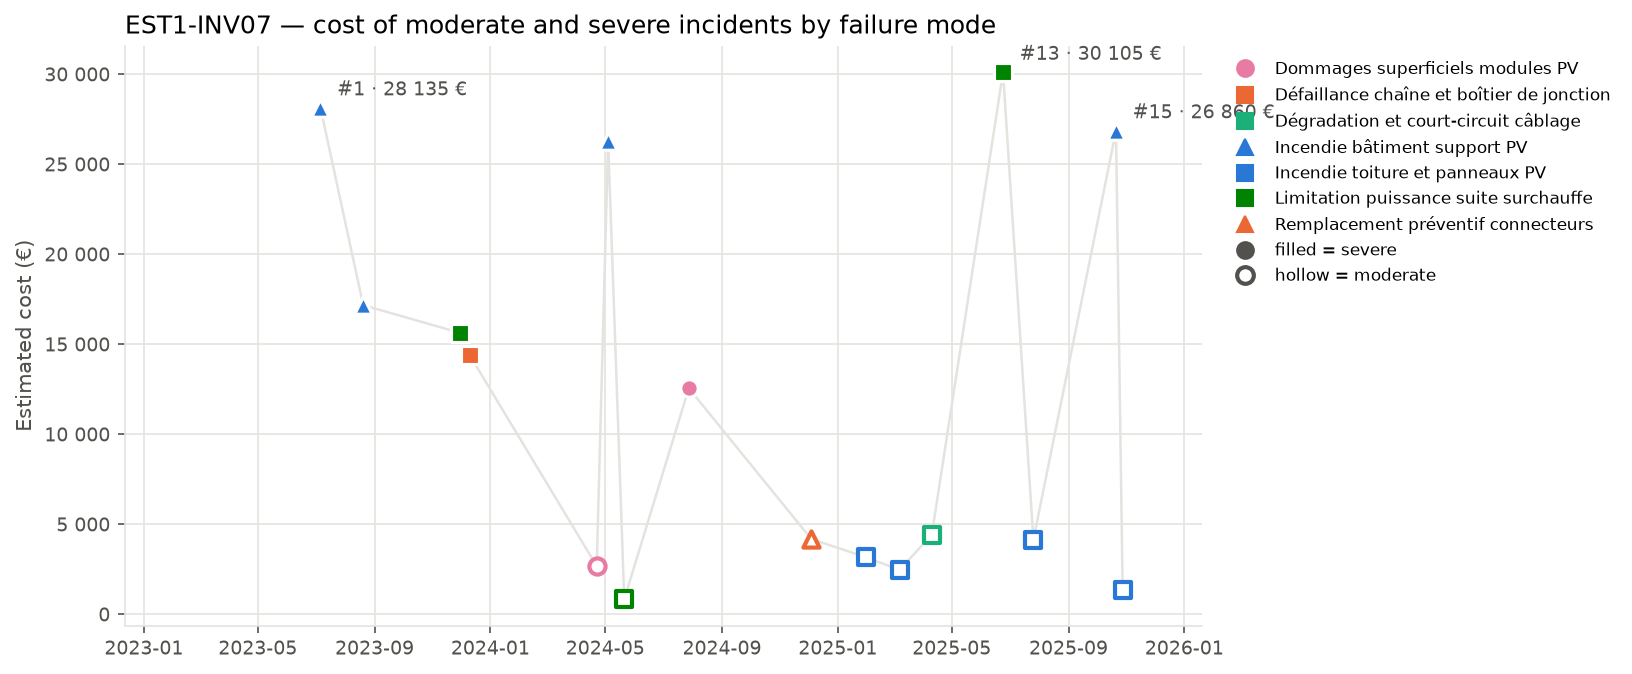

# EST1-INV07 Critical Failure Modes: Fire and Overheating

**Equipment:** EST1-INV07 · **Site:** Centrale PV Est-1 · **Asset type:** PV inverter · **Generated on:** 2026-10-20

> The PV inverter EST1-INV07 at Centrale PV Est-1 faces critical risks primarily from incendie bâtiment support PV and limitation puissance suite surchauffe failure modes. These incidents have resulted in significant costs, with the most costly failure mode accounting for over half of the total incident-related expenses. Given its high criticality score and ranking within the site, immediate focus should be on implementing regular thermography inspections and fire-risk assessments to mitigate these high-priority failure modes.

**Equipment priority: P1 · Risk level: CRITICAL** — Criticality score 99.6 (at or above the threshold of 75) against the other equipment of the site and 90.4 (at or above the threshold of 75) against the whole solar fleet.

---

## 1. Key figures

| Indicator | This equipment | Median equipment of the site | Ratio |
| --- | --- | --- | --- |
| Incidents (all severities) | 29 | 24.5 | ×1.18 |
| Severe incidents | 8 | 3.0 | ×2.67 |
| Total estimated cost (all severities) | 199 323 EUR | 83 380 EUR | ×2.39 |
| Total downtime (all severities) | 404.0 h | 199.4 h | ×2.03 |

| Moderate and severe incidents (scope of this report) | Value |
| --- | --- |
| Incidents analysed | 16 (8 moderate · 8 severe) |
| Period covered | 2023-07-06 → 2025-11-15 |
| Total estimated cost | 194 387 EUR (88.1 % from severe incidents) |
| Average cost per incident | 12 149 EUR |
| Total downtime | 381.7 h |
| Average interval between incidents | 56 days |
| Most costly failure mode | Incendie bâtiment support PV (98 449 EUR) |
| Weather with most downtime | vent modéré (94.9 h) |

This equipment, EST1-INV07, stands out from the median equipment of its site on several indicators. It has a higher number of incidents of all severities with a ratio of 1.18, and a significantly higher number of severe incidents with a ratio of 2.67. Its associated costs are also notably higher, with a ratio of 2.39, and its downtime exceeds the median by a ratio of 2.03. It was selected because of its criticality score of 99.6, which is well above the threshold of 75, indicating its high importance within the site and the entire fleet. The criticality score and the high incident and cost ratios highlight its priority for attention. The cost is heavily concentrated on severe incidents, which account for 88.1% of the total incident-related costs, underscoring the impact of the most serious failures.

## 2. How this report was built

**Scope.** This report covers the maintenance incidents recorded on EST1-INV07 between 2023-07-06 and 2025-11-15. Each incident report was read and assigned to a *failure mode* according to its description. The detailed analysis focuses on moderate and severe incidents; minor incidents only appear in the comparison with the site. Incidents are numbered #1, #2, … in chronological order for this equipment (see the annex).

**Why this equipment.** Each piece of equipment receives a criticality score from 0 to 100 that combines four indicators: number of incidents, number of severe incidents (counted twice), total repair cost and total downtime. The score is computed twice: against the other equipment of the same site and against all solar equipment of the fleet. 50 corresponds to a typical piece of equipment, 75 or more to one clearly above the others. Equipment scoring 75 or more on both comparisons is priority **P1**, on one of them priority **P2**. Here: criticality score 99.6 (at or above the threshold of 75) against the other equipment of the site and 90.4 (at or above the threshold of 75) against the whole solar fleet → **P1**.

**Recommendation priority.** Each recommendation addresses one failure mode and inherits its priority:
- **P1** — within 1 month: the failure mode caused at least one severe incident on this equipment and either represents 

*[…truncated]*

In [24]:
display(Image(filename=equipment_dir_2 / "figures" / "cost_timeline.png"))
show_markdown(equipment_dir_2 / "report.md", max_chars=4000)

To keep the reports of a new site in the repository, run the command without a temporary folder
(`uv run dc-equipment --site EST1`): the outputs go to `equipment_reports/EST1/`.